In [11]:
import torch
import torch.nn as nn
from torchvision import transforms
from sklearn.preprocessing import LabelEncoder
from torchvision.models import resnet18
from torch.utils.data import Dataset,DataLoader
from sklearn.model_selection import train_test_split
from torch.optim import Adam
import numpy as np
import pandas as pd
from torchsummary import summary
from PIL import Image
import matplotlib.pyplot as plt
import os
device = "cuda" if torch.cuda.is_available() else "cpu" # detect the GPU if any, if not use CPU, change cuda to mps if you have a mac
print("Device available: ", device)
print(torch.cuda.get_device_name(0))


Device available:  cuda
Tesla T4


In [12]:
image_path=[]
labels=[]
root_dir=r"/kaggle/input/datasets/anshul1802/mri-data/mri"
for i in os.listdir(root_dir):
    for label in os.listdir(os.path.join(root_dir,i)):
        for image in os.listdir(os.path.join(root_dir,i,label)):
            image_path.append(os.path.join(root_dir,i,label,image))
            labels.append(label)

data_df=pd.DataFrame(zip(image_path,labels),columns=["image_path","labels"])
data_df.head()



,image_path,labels
0,/kaggle/input/datasets/anshul1802/mri-data/mri...,pituitary
1,/kaggle/input/datasets/anshul1802/mri-data/mri...,pituitary
2,/kaggle/input/datasets/anshul1802/mri-data/mri...,pituitary
3,/kaggle/input/datasets/anshul1802/mri-data/mri...,pituitary
4,/kaggle/input/datasets/anshul1802/mri-data/mri...,pituitary


In [13]:
train=data_df.sample(frac=0.8)
test=data_df.drop(train.index)
validation=test.sample(frac=0.5)
test=test.drop(validation.index)
print(train.shape)
print(validation.shape)
print(test.shape)

(5760, 2)
(720, 2)
(720, 2)


In [14]:
label_encoder=LabelEncoder()
label_encoder.fit(data_df["labels"])
transform=transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.ConvertImageDtype(torch.float32)
])
class customdataset(Dataset):
    def __init__(self,dataframe,transform=None):
        self.dataframe=dataframe
        self.transform=transform
        self.labels=torch.tensor(label_encoder.fit_transform(dataframe['labels']))

    def __len__(self):
        return self.dataframe.shape[0]
    
    def __getitem__(self, index):
        img_path=self.dataframe.iloc[index,0]
        labels=self.labels[index]
        image=Image.open(img_path).convert('RGB')
        if self.transform:
            image=self.transform(image).to(device)
            return image,labels

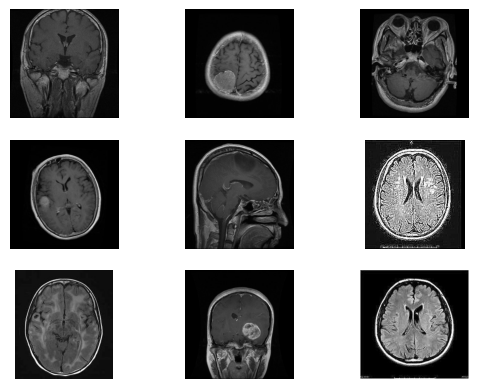

array(['glioma'], dtype=object)

In [15]:
train_dataset=customdataset(dataframe=train,transform=transform)
test_dataset=customdataset(dataframe=test,transform=transform)
validation_dataset=customdataset(dataframe=validation,transform=transform)

n_rows = 3
n_cols = 3

f, axarr = plt. subplots(n_rows, n_cols)

for row in range(n_rows):
  for col in range(n_cols):
    image = Image.open(data_df.sample(n = 1) ["image_path"].iloc[0]).convert("RGB")
    axarr [row, col] . imshow( image)
    axarr[row, col].axis('off')

plt.show()
label_encoder.inverse_transform([0])

In [16]:
LR=0.005
BATCH_SIZE=20
EPOCHS=50

In [17]:
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=True)
validation_loader=DataLoader(validation_dataset,batch_size=BATCH_SIZE,shuffle=True)

In [18]:
mymodel=resnet18(weights='DEFAULT').to(device)
mymodel.fc
num_classes=len(train["labels"].unique())
for param in mymodel.parameters():
    param.requires_grad=True

mymodel.fc=nn.Linear(mymodel.fc.in_features,num_classes).to(device)
mymodel.fc

Linear(in_features=512, out_features=4, bias=True)

In [19]:
criteria=nn.CrossEntropyLoss()
optimizer=Adam(mymodel.parameters(),lr=LR)

In [20]:
total_loss_train_plot=[]
total_loss_validation_plot=[]
total_accuracy_train_plot=[]
total_accuracy_validation_plot=[]


for epoch in range(EPOCHS):
    total_loss_train=0
    total_loss_validation=0
    total_accuracy_train=0
    total_accuracy_validation=0
    best_val_acc=0
    mymodel.train()
    for inputs,labels in train_loader:
        inputs=inputs.to(device)
        labels=labels.to(device)
        optimizer.zero_grad()
        output=mymodel(inputs)
        train_loss=criteria(output,labels)
        total_loss_train+=train_loss.item()
        train_loss.backward()

        train_acc=(torch.argmax(output,axis=1)==labels).sum().item()
        total_accuracy_train+=train_acc
        optimizer.step()
    with torch.no_grad():
        mymodel.eval()
        for inputs,labels in validation_loader:
            inputs=inputs.to(device)
            labels=labels.to(device)
            output=mymodel(inputs)
            val_loss=criteria(output,labels)
            total_loss_validation+=val_loss.item()
            acc_val=(torch.argmax(output,axis=1)==labels).sum().item()
            total_accuracy_validation+=acc_val
            if acc_val>best_val_acc:
                best_val_acc=acc_val
                torch.save({'epoch':epoch,
                  'model_state_dict':mymodel.state_dict(),
                  'optimizer_state_dict':optimizer.state_dict(),
                  'val_loss':round((total_loss_validation/len(validation_loader))*100,4),
                  'val_acc':round((total_accuracy_validation/len(validation_dataset))*100,4)},'best_mrimodel.pth')
                
    total_loss_train_plot.append(round(total_loss_train/1000, 4))
    total_loss_validation_plot.append(round(total_loss_validation/1000, 4))
    total_accuracy_train_plot.append(round( (total_accuracy_train/train_dataset.__len__()) * 100, 4))
    total_accuracy_validation_plot.append(round( (total_accuracy_validation/validation_dataset.__len__()) * 100, 4))

    print(f"epoch no:{epoch+1}/{EPOCHS} TOTAL LOSS :{round(total_loss_train/1000, 4)} TOTAL VALIDATION LOSS :{round(total_loss_validation/1000, 4)} TOTAL ACCURACY :{round( (total_accuracy_train/train_dataset.__len__() )* 100, 4)} TOTAL VALIDATION ACCURACY :{round( (total_accuracy_validation/validation_dataset.__len__()) * 100, 4)}")





epoch no:1/50 TOTAL LOSS :0.2964 TOTAL VALIDATION LOSS :0.0836 TOTAL ACCURACY :60.3819 TOTAL VALIDATION ACCURACY :59.7222
epoch no:2/50 TOTAL LOSS :0.2027 TOTAL VALIDATION LOSS :0.0234 TOTAL ACCURACY :74.3403 TOTAL VALIDATION ACCURACY :72.0833
epoch no:3/50 TOTAL LOSS :0.1828 TOTAL VALIDATION LOSS :0.0218 TOTAL ACCURACY :77.1528 TOTAL VALIDATION ACCURACY :76.6667
epoch no:4/50 TOTAL LOSS :0.1495 TOTAL VALIDATION LOSS :0.0136 TOTAL ACCURACY :80.3646 TOTAL VALIDATION ACCURACY :86.5278
epoch no:5/50 TOTAL LOSS :0.1133 TOTAL VALIDATION LOSS :0.0115 TOTAL ACCURACY :85.6424 TOTAL VALIDATION ACCURACY :89.5833
epoch no:6/50 TOTAL LOSS :0.0973 TOTAL VALIDATION LOSS :0.0227 TOTAL ACCURACY :87.4653 TOTAL VALIDATION ACCURACY :73.75
epoch no:7/50 TOTAL LOSS :0.0684 TOTAL VALIDATION LOSS :0.0079 TOTAL ACCURACY :91.4931 TOTAL VALIDATION ACCURACY :92.9167
epoch no:8/50 TOTAL LOSS :0.0561 TOTAL VALIDATION LOSS :0.0287 TOTAL ACCURACY :93.1597 TOTAL VALIDATION ACCURACY :74.8611
epoch no:9/50 TOTAL LOSS :